In [ ]:
import os
# https://stackoverflow.com/questions/20554074/sklearn-omp-error-15-initializing-libiomp5md-dll-but-found-mk2iomp5md-dll-a
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

import matplotlib.pyplot as plt


import cv2

import importlib
import sys
from pathlib import Path
if os.name == 'nt':
    sys.path.append(os.getcwd() + "\\..\\src")    
else:
    sys.path.append(os.getcwd() + "/../src")

import numpy as np

In [5]:
img1 = plt.imread('assets/test_distributions/complex.jpg')[:, :, 0] # Specify the path to your image here
img2 = plt.imread('assets/test_distributions/Checkerboard.png') # Specify the path to your image here


(360, 720)
(2048, 2048)


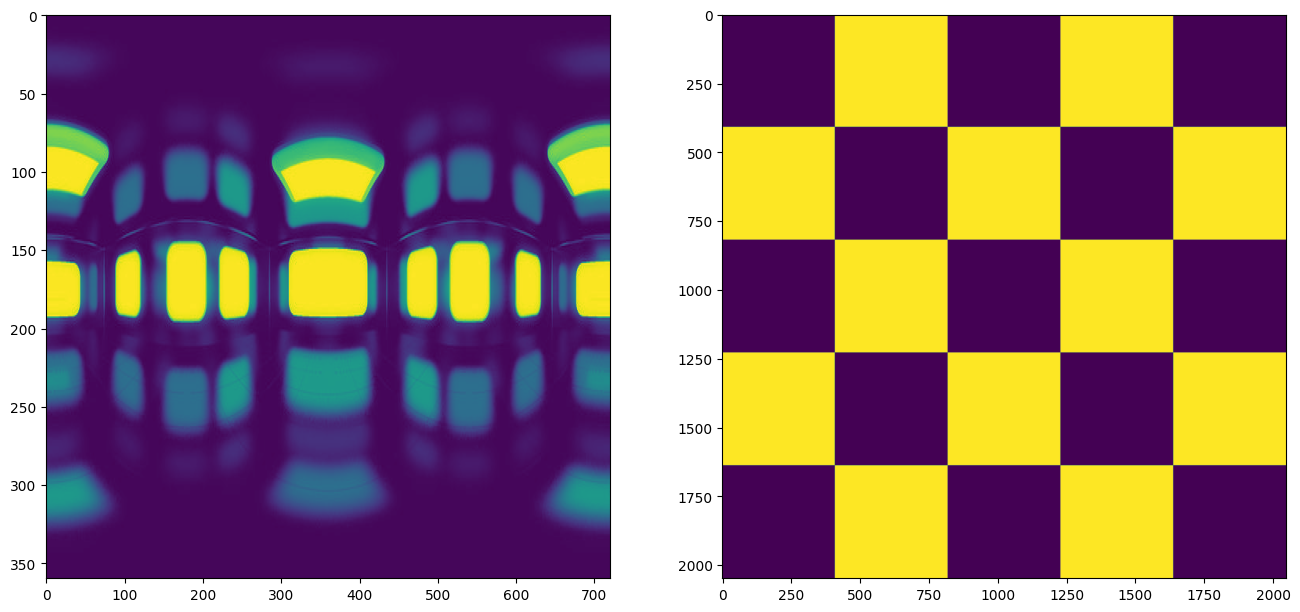

In [13]:
# xx, yy = torch.meshgrid(torch.linspace(-3, 3, grid_size), torch.linspace(-3, 3, grid_size))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

print(img1.shape)
print(img2.shape)

im1_shape = img1.shape

# ax1.pcolormesh(xx, yy, prob.data.numpy())
ax1.imshow(img1, aspect = im1_shape[1] / im1_shape[0])
ax2.imshow(img2)
plt.show()

In [47]:
print(img2[500, 250])

1.0


In [40]:
def interpolate_images(img1, img2, t):
    s1 = img1.shape
    s2  =img2.shape

    x_size = max(s1[0], s2[0])
    y_size = max(s1[1], s2[1])

    img1_resized = cv2.resize(img1, (x_size, y_size), interpolation=cv2.INTER_CUBIC)
    img2_resized = cv2.resize(img2, (x_size, y_size), interpolation=cv2.INTER_CUBIC)


    # ## Not completely tested yet, works if one image is larger in both dimensions
    # print(img1_resized.shape)
    # print(img2_resized.shape)

    return (1 - t) * img1_resized + t * img2_resized


def interpolate_images_by_coords(img1, img2, coords, t):
    coords1 = (coords * img1.shape).astype(np.uint32)
    coords2 = (coords * img2.shape).astype(np.uint32)

    return (1 - t) * img1[coords1[0], coords1[1]] + t * img2[coords2[0], coords2[1]]

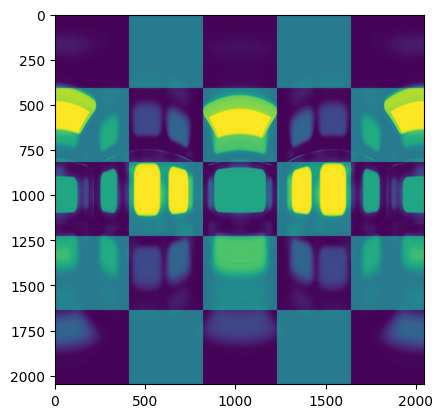

: 

In [ ]:
interpolated = interpolate_images(img1, img2 * 255, 0.4)

plt.imshow(interpolated)